# 10 · Ensembling and stacking

Averaging the predictions of different models reduces error when their **errors are not perfectly correlated**.
For two models with equal error variance $\sigma^2$ and error correlation $\rho$, the average has error variance $\sigma^2 \frac{1+\rho}{2}$. Diversity is what you're buying.

| Method | How | When |
|---|---|---|
| Simple average | mean of predictions (or of probabilities) | always try first; hard to overfit |
| Weighted average | weights fit on out-of-fold (OOF) predictions | when models differ clearly in quality |
| Stacking | a meta-model (usually Ridge/logistic) trained on OOF predictions | when you have several diverse models |
| Seed/fold averaging | same model, different seeds or CV folds | cheap variance reduction for boosting |

**The key rule:** the second-level model must be trained on **out-of-fold** predictions, i.e. predictions on rows each base model didn't see. Otherwise it learns to trust the most overfit model.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)

# One consistent, colour-blind-friendly style for every notebook.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
GREY = "#a3a29c"
plt.rcParams.update({
    "figure.figsize": (8, 4.5), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.8,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})
pd.set_option("display.precision", 4)

In [2]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import KFold, train_test_split
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, SplineTransformer
from sklearn.linear_model import RidgeCV, LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
import lightgbm as lgb
from catboost import CatBoostRegressor

X, y = fetch_california_housing(return_X_y=True, as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
rmse = lambda a, b: float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

## 1. Out-of-fold predictions

For each base model: train on K−1 folds, predict the held-out fold, and also predict the test set. Average the K test predictions.

In [3]:
def get_oof(model, X, y, X_test, n_splits=5):
    oof = np.zeros(len(X)); test_pred = np.zeros(len(X_test))
    for tr, va in KFold(n_splits, shuffle=True, random_state=SEED).split(X):
        m = clone(model).fit(X.iloc[tr], y.iloc[tr])
        oof[va] = m.predict(X.iloc[va])
        test_pred += m.predict(X_test) / n_splits
    return oof, test_pred

base_models = {
    "ridge_splines": make_pipeline(SplineTransformer(n_knots=8), RidgeCV(alphas=np.logspace(-3, 3, 20))),
    "knn": make_pipeline(StandardScaler(), KNeighborsRegressor(10, weights="distance")),
    "random_forest": RandomForestRegressor(300, max_features=0.5, min_samples_leaf=2, n_jobs=-1, random_state=SEED),
    "lightgbm": lgb.LGBMRegressor(n_estimators=1000, learning_rate=0.03, num_leaves=63, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1),
    "catboost": CatBoostRegressor(iterations=1500, learning_rate=0.08, depth=8, random_seed=SEED, verbose=0),
}
oof, test_preds = {}, {}
for name, m in base_models.items():
    oof[name], test_preds[name] = get_oof(m, X_train, y_train, X_test)
oof, test_preds = pd.DataFrame(oof, index=X_train.index), pd.DataFrame(test_preds, index=X_test.index)

scores = pd.DataFrame({"OOF RMSE": [rmse(y_train, oof[c]) for c in oof], "test RMSE": [rmse(y_test, test_preds[c]) for c in oof]}, index=oof.columns)
scores

,OOF RMSE,test RMSE
ridge_splines,0.7001,0.6619
knn,0.6362,0.6398
random_forest,0.4995,0.5008
lightgbm,0.4421,0.4282
catboost,0.4413,0.4266


## 2. How correlated are the errors?
Low correlation = more to gain from combining.

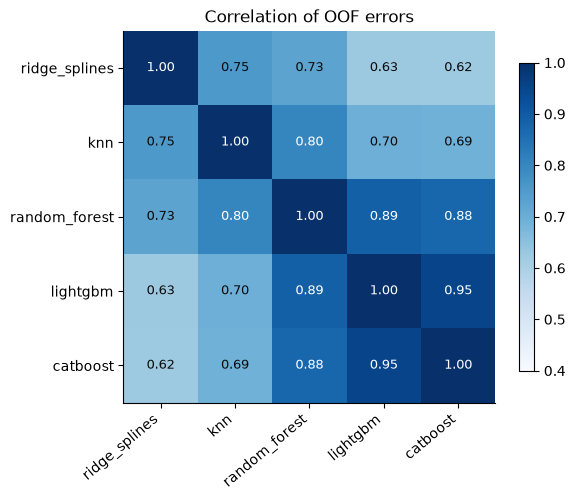

In [4]:
err_corr = oof.sub(y_train, axis=0).corr()
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(err_corr, cmap="Blues", vmin=0.4, vmax=1)
ax.set_xticks(range(len(err_corr)), err_corr.columns, rotation=40, ha="right"); ax.set_yticks(range(len(err_corr)), err_corr.columns)
for i in range(len(err_corr)):
    for j in range(len(err_corr)):
        v = err_corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9, color="white" if v > 0.8 else "#0b0b0b")
ax.grid(False); ax.set_title("Correlation of OOF errors"); fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

## 3. Averaging, weighting, stacking

In [5]:
from scipy.optimize import nnls

results = {name: rmse(y_test, test_preds[name]) for name in ["lightgbm", "catboost"]}

# Simple averages
results["avg: lightgbm + catboost"] = rmse(y_test, test_preds[["lightgbm", "catboost"]].mean(1))
results["avg: all 5"] = rmse(y_test, test_preds.mean(1))

# Non-negative weights fit on OOF (non-negative least squares), then normalised
w, _ = nnls(oof.values, y_train.values)
w = w / w.sum()
results["weighted (NNLS on OOF)"] = rmse(y_test, test_preds.values @ w)
print("NNLS weights:", {k: round(float(v), 3) for k, v in zip(oof.columns, w)})

# Stacking: linear meta-model on OOF predictions (positive=True keeps it sane)
meta = LinearRegression(positive=True).fit(oof, y_train)
results["stack: linear meta-model"] = rmse(y_test, meta.predict(test_preds))

# Stacking with original features too: lets the meta-model trust different models in different regions
meta_gbm = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.03, num_leaves=15, random_state=SEED, verbose=-1)
meta_gbm.fit(pd.concat([oof, X_train], axis=1), y_train)
results["stack: LGBM meta on OOF + features"] = rmse(y_test, meta_gbm.predict(pd.concat([test_preds, X_test], axis=1)))

pd.Series(results, name="test RMSE").sort_values().round(4).to_frame()

NNLS weights: {'ridge_splines': 0.0, 'knn': 0.0, 'random_forest': 0.0, 'lightgbm': 0.48, 'catboost': 0.52}


,test RMSE
stack: LGBM meta on OOF + features,0.4240
stack: linear meta-model,0.4244
weighted (NNLS on OOF),0.4246
avg: lightgbm + catboost,0.4246
catboost,0.4266
lightgbm,0.4282
avg: all 5,0.4875


Two lessons in that table. First, **naively averaging in much weaker models hurts** ("avg: all 5"): equal weights give the weak models too much say. The OOF-fitted weights and stacks avoid this automatically, and here NNLS gives the weak models ~0 weight. Second, gains from combining strong, different models (LightGBM + CatBoost) are modest (~1%) but very reliable. In competitions they decide rankings; in production weigh them against the extra complexity.

## 4. The one-liner: sklearn `StackingRegressor`
It does the OOF bookkeeping for you (`StackingClassifier` for classification, which stacks predicted probabilities).

In [6]:
from sklearn.ensemble import StackingRegressor

stack = StackingRegressor(
    estimators=[(n, base_models[n]) for n in ["ridge_splines", "random_forest", "lightgbm"]],
    final_estimator=RidgeCV(), cv=5, n_jobs=1,
)
stack.fit(X_train, y_train)
print(f"StackingRegressor test RMSE: {rmse(y_test, stack.predict(X_test)):.4f}")
print("meta weights:", {k: round(float(v), 3) for k, v in zip(["ridge_splines", "random_forest", "lightgbm"], stack.final_estimator_.coef_)})

StackingRegressor test RMSE: 0.4286
meta weights: {'ridge_splines': 0.013, 'random_forest': 0.0, 'lightgbm': 0.991}


## Takeaways
- Diversity helps only among *competitive* models; weak models belong in a weighted/stacked blend, not a plain average.
- Always build the second level on **OOF predictions**, with the **same folds** for every base model.
- Start with a simple average; move to NNLS weights or a constrained linear stack.
- For classification, average probabilities (or log-odds), and evaluate with log loss/AUC.
- Group or time structure? Generate OOF with the matching splitter (`GroupKFold`, walk-forward).